## Lectura del csv

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
df = pd.read_csv('product_activity.csv')

## Exploracion inicial:
**utilizacion de head(), info() y describe() para comprender mejor el contenido del dataset**

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8782 entries, 0 to 8781
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   user_id            8782 non-null   str    
 1   created_at         8782 non-null   str    
 2   country            8782 non-null   str    
 3   plan_type          8782 non-null   str    
 4   user_age           8028 non-null   float64
 5   post_id            8782 non-null   str    
 6   post_category      8782 non-null   str    
 7   post_created_at    8782 non-null   str    
 8   votes_received     8782 non-null   int64  
 9   user_total_posts   8782 non-null   int64  
 10  days_since_signup  8782 non-null   int64  
 11  device_type        8782 non-null   str    
dtypes: float64(1), int64(3), str(8)
memory usage: 823.4 KB


In [3]:
df.head()

,user_id,created_at,country,plan_type,user_age,post_id,post_category,post_created_at,votes_received,user_total_posts,days_since_signup,device_type
0,U01988,2025-02-18T02:07:44,PY,pro,26.0,P0008515,sport,2025-05-07T20:55:28,7,16,78,mobile
1,U00236,2025-06-22T07:49:10,BR,free,27.0,P0001023,tech,2025-09-13T20:31:06,1,9,83,web
2,U00791,2024-02-12T02:45:45,CL,free,28.0,P0003405,tech,2024-02-14T05:17:48,11,2,2,mobile
3,U01522,2024-09-22T07:06:50,US,free,16.0,P0006524,finance,2024-09-24T07:51:34,5,2,2,web
4,U01092,2025-07-18T02:27:52,PY,free,NaN,P0004665,education,2025-07-24T04:56:56,7,2,6,mobile


In [4]:
df.describe()

,user_age,votes_received,user_total_posts,days_since_signup
count,8028.000000,8782.000000,8782.000000,8782.000000
mean,27.902591,6.918356,8.324186,29.479390
std,7.547052,5.127311,6.754906,36.819928
min,16.000000,0.000000,1.000000,0.000000
25%,22.000000,3.000000,4.000000,5.000000
50%,28.000000,6.000000,6.000000,17.000000
75%,33.000000,9.000000,11.000000,40.000000
max,58.000000,74.000000,39.000000,404.000000


**Conteo de nulos y duplicados exactos**

In [5]:
duplicates = df.duplicated().sum()
null_values = df.isnull().sum()
print(f'Total de filas duplicadas: {duplicates}')
print(f'Valores nulos por columna:\n{null_values}')

Total de filas duplicadas: 172
Valores nulos por columna:
user_id                0
created_at             0
country                0
plan_type              0
user_age             754
post_id                0
post_category          0
post_created_at        0
votes_received         0
user_total_posts       0
days_since_signup      0
device_type            0
dtype: int64


**Valores unicos y frecuencias de plan_type, post_category y device_type**

In [6]:
display(pd.DataFrame(df['plan_type'].value_counts()))
display(pd.DataFrame(df['post_category'].value_counts()))
display(pd.DataFrame(df['device_type'].value_counts()))

,count
plan_type,
free,5978
pro,1460
enterprise,306
Free,208
free,197
FREE,196
FreE,189
PRo,46
pro,44


,count
post_category,
tech,1187
life,913
sports,899
science,753
finance,739
gaming,727
music,614
health,601
education,592


,count
device_type,
web,4416
mobile,3761
desktop,602
tablet,1
console,1
phone,1


**Chequeos logicos: conversion de fechas y calculo de inconsistencias en days_since_signup** <br>
 *finalizacion de la Exploracion Inicial*

In [7]:
df['created_at'] = pd.to_datetime(df['created_at'], errors="coerce")
df['post_created_at'] = pd.to_datetime(df['post_created_at'], errors="coerce")

In [8]:
before_signup_days = (df['post_created_at'] < df['created_at']).sum()
inconsistency_days_count = ((df['post_created_at'] - df['created_at']).dt.days != df['days_since_signup']).sum()
print(f'cantidad de posts registrados antes del signup: {before_signup_days}')
print(f'cantidad de inconsistencias de registro en days_since_signup: {inconsistency_days_count}')

cantidad de posts registrados antes del signup: 100
cantidad de inconsistencias de registro en days_since_signup: 4479


## Limpieza basica con criterio
**Depuracion de duplicados**

In [9]:
df = df.drop_duplicates()
print(f'Luego de la depuracion de duplicados nos quedamos con {len(df)} filas y {df.shape[1]} columnas')

Luego de la depuracion de duplicados nos quedamos con 8610 filas y 12 columnas


**Normalizacion canonica**

In [10]:
df['post_category'] = df['post_category'].str.lower().str.strip()
category_map = {
    'tehc': 'tech',
    'sporst': 'sports',
    'sp0rts': 'sports',
    'sport': 'sports',
    'lfe': 'life',
    'sciense': 'science',
    'gamming': 'gaming',
    'finanse': 'finance',
    'educatoin': 'education',
    'healt': 'health',
    'trvael': 'travel',
    'musc': 'music'
}
df['post_category'] = df['post_category'].replace(category_map)
df['plan_type'] = df['plan_type'].str.lower().str.strip()
plan_type_map = {
    "enterprise+" : "enterprise"
}
df['plan_type'] = df['plan_type'].replace(plan_type_map)
df['device_type'] = df['device_type'].str.lower().str.strip()
device_type_map = {
    "phone": "mobile"
}
df['device_type'] = df['device_type'].replace(device_type_map)
print(df['post_category'].value_counts())
print(df['plan_type'].value_counts())
print(df['device_type'].value_counts())
print(f'Duplicados después de normalizar: {df.duplicated().sum()}')

post_category
tech         1397
life         1039
sports       1028
science       882
finance       865
gaming        844
education     687
music         685
health        681
travel        500
politics        1
mistery         1
Name: count, dtype: int64
plan_type
free          6637
pro           1631
enterprise     340
premium          1
vip              1
Name: count, dtype: int64
device_type
web        4328
mobile     3689
desktop     591
tablet        1
console       1
Name: count, dtype: int64
Duplicados después de normalizar: 0


In [11]:
df['reason_code'] = ''
valid_plan = {'free', 'pro', 'enterprise'}
valid_device = {'web', 'mobile', 'desktop'}
valid_category = {'tech', 'life', 'sports', 'science', 'finance', 'gaming', 'education', 'music', 'health', 'travel'}
invalid_plan = ~df["plan_type"].isin(valid_plan)
invalid_device = ~df["device_type"].isin(valid_device)
invalid_category = df["post_category"].isna() | ~df["post_category"].isin(valid_category)
quarantine = {
    "invalid_plan": invalid_plan,
    "invalid_device": invalid_device,
    "invalid_category": invalid_category,
    "post_before_signup": df["post_created_at"] < df["created_at"],
    "invalid_dates": df["created_at"].isna() | df["post_created_at"].isna()
}

for reason, condition in quarantine.items():

    df.loc[condition, "reason_code"] += reason + ";"

# separar filas en quarantine y core
is_quarantine = df["reason_code"] != ""
df_quarantine = df[is_quarantine].copy()
df_clean = df[~is_quarantine].drop(columns=["reason_code"]).copy()

print(f"filas en quarantine: {len(df_quarantine)}")
print(f"filas en clean: {len(df_clean)}")

filas en quarantine: 101
filas en clean: 8509


In [12]:
# 1. Recalcular días desde el signup (post - signup)
df_clean['days_since_signup_calc'] = (df_clean['post_created_at'] - df_clean['created_at']).dt.days

# 2. Chequeo de cordura: no debería haber negativos
print(f"Mínimo de days_since_signup_calc: {df_clean['days_since_signup_calc'].min()}")

# 3. Comparar contra la original
diff = df_clean['days_since_signup_calc'] - df_clean['days_since_signup']
mismatches = (diff != 0).sum()
mismatch_pct = mismatches / len(df_clean) * 100
print(f"Filas con desfase: {mismatches} ({mismatch_pct:.1f}%)")

# 4. De cuánto son los desfases
print(diff[diff != 0].describe())

Mínimo de days_since_signup_calc: 0
Filas con desfase: 4303 (50.6%)
count    4303.000000
mean       -0.993725
std         0.405343
min        -4.000000
25%        -1.000000
50%        -1.000000
75%        -1.000000
max         3.000000
dtype: float64


In [13]:
rows_raw = len(pd.read_csv('product_activity.csv'))
rows_clean = len(df_clean)
rows_quarantine = len(df_quarantine)
duplicates_removed = rows_raw - len(df)
quarantine_pct = rows_quarantine / len(df) * 100

print(f"Filas RAW: {rows_raw}")
print(f"Duplicados removidos: {duplicates_removed}")
print(f"Filas en CORE: {rows_clean}")
print(f"Filas en cuarentena: {rows_quarantine} ({quarantine_pct:.1f}%)")
print(f"Desfase en days_since_signup: {mismatch_pct:.1f}%")
print(df_quarantine['reason_code'].value_counts())

Filas RAW: 8782
Duplicados removidos: 172
Filas en CORE: 8509
Filas en cuarentena: 101 (1.2%)
Desfase en days_since_signup: 50.6%
reason_code
post_before_signup;                              95
invalid_dates;                                    2
invalid_plan;                                     1
invalid_device;                                   1
invalid_category;                                 1
invalid_plan;invalid_device;invalid_category;     1
Name: count, dtype: int64


In [14]:
users_per_plan = df_clean.groupby('plan_type')['user_id'].nunique()
posts_by_country = df_clean['country'].value_counts()
posts_by_category = df_clean['post_category'].value_counts()
posts_by_device = df_clean['device_type'].value_counts()

print(users_per_plan)
print(posts_by_country)
print(posts_by_category)
print(posts_by_device)

plan_type
enterprise      83
free          1546
pro            367
Name: user_id, dtype: int64
country
US    1873
BR    1600
AR    1168
PY     837
MX     802
CL     552
ES     547
CO     489
PE     393
UY     248
Name: count, dtype: int64
post_category
tech         1382
life         1034
sports       1017
science       870
finance       853
gaming        833
education     682
health        673
music         673
travel        492
Name: count, dtype: int64
device_type
web        4270
mobile     3657
desktop     582
Name: count, dtype: int64


In [15]:
votes_by_plan = df_clean.groupby('plan_type')['votes_received'].describe(percentiles=[0.5, 0.9, 0.99])
votes_by_country = df_clean.groupby('country')['votes_received'].agg(['mean', 'median'])
votes_by_category = df_clean.groupby('post_category')['votes_received'].agg(['mean', 'median'])
votes_by_device = df_clean.groupby('device_type')['votes_received'].agg(['mean', 'median'])

print(votes_by_plan)
print(votes_by_country)
print(votes_by_category)
print(votes_by_device)

             count      mean       std  min  50%   90%    99%   max
plan_type                                                          
enterprise   334.0  7.547904  4.907778  0.0  7.0  14.0  23.34  26.0
free        6568.0  6.693057  5.028762  0.0  6.0  13.0  23.00  74.0
pro         1607.0  7.654014  5.490376  0.0  7.0  14.0  25.00  50.0
             mean  median
country                  
AR       6.771404     6.0
BR       6.889375     6.0
CL       7.311594     6.0
CO       7.308793     6.0
ES       6.981718     6.0
MX       6.962594     6.0
PE       6.547074     6.0
PY       6.600956     6.0
US       6.973305     6.0
UY       6.762097     6.0
                   mean  median
post_category                  
education      6.781525     6.0
finance        6.978898     6.0
gaming         7.186074     6.0
health         6.456166     6.0
life           6.173114     5.0
music          6.286776     5.0
science        7.544828     6.0
sports         6.573255     6.0
tech           7.688133     

In [16]:
posts_per_user = df_clean.groupby('user_id').size()
print(f"Posts por usuario - promedio: {posts_per_user.mean():.2f}, mediana: {posts_per_user.median()}, máximo: {posts_per_user.max()}")

avg_user_total_rows = df_clean['user_total_posts'].mean()
avg_user_total_users = df_clean.groupby('user_id')['user_total_posts'].first().mean()
print(f"user_total_posts promedio por fila: {avg_user_total_rows:.2f}")
print(f"user_total_posts promedio por usuario: {avg_user_total_users:.2f}")

Posts por usuario - promedio: 4.26, mediana: 3.0, máximo: 39
user_total_posts promedio por fila: 8.29
user_total_posts promedio por usuario: 4.31


In [17]:
avg_votes_row = df_clean['votes_received'].mean()
votes_per_user = df_clean.groupby('user_id')['votes_received'].mean()
avg_votes_user = votes_per_user.mean()

print(f"Promedio de votos por fila (post): {avg_votes_row:.2f}")
print(f"Promedio de votos por usuario: {avg_votes_user:.2f}")

Promedio de votos por fila (post): 6.91
Promedio de votos por usuario: 6.89


In [18]:
user_posts = df_clean.groupby('user_id').size().sort_values(ascending=False)
user_votes = df_clean.groupby('user_id')['votes_received'].sum().sort_values(ascending=False)

top_n = max(1, int(len(user_posts) * 0.01))
top_posts_pct = user_posts.head(top_n).sum() / user_posts.sum() * 100
top_votes_pct = user_votes.head(top_n).sum() / user_votes.sum() * 100

print(f"Top 1% de usuarios ({top_n} usuarios):")
print(f"  % de posts: {top_posts_pct:.1f}%")
print(f"  % de votos: {top_votes_pct:.1f}%")

Top 1% de usuarios (19 usuarios):
  % de posts: 5.8%
  % de votos: 6.2%


In [19]:
df_clean['month'] = df_clean['post_created_at'].dt.to_period('M')
df_clean['week'] = df_clean['post_created_at'].dt.to_period('W')

monthly = df_clean.groupby('month').agg(posts=('post_id', 'count'), avg_votes=('votes_received', 'mean'))
weekly = df_clean.groupby('week').agg(posts=('post_id', 'count'), avg_votes=('votes_received', 'mean'))

print(monthly)
print(weekly.head())

         posts  avg_votes
month                    
2024-01    195   7.056410
2024-02    370   7.040541
2024-03    387   6.627907
2024-04    394   6.979695
2024-05    456   6.800439
2024-06    389   6.776350
2024-07    380   7.134211
2024-08    388   6.703608
2024-09    304   6.677632
2024-10    353   7.237960
2024-11    364   6.552198
2024-12    374   6.791444
2025-01    398   6.841709
2025-02    299   7.096990
2025-03    340   6.823529
2025-04    382   6.717277
2025-05    354   7.251412
2025-06    316   6.607595
2025-07    349   6.719198
2025-08    372   7.201613
2025-09    373   7.198391
2025-10    287   7.191638
2025-11    294   6.942177
2025-12    391   6.971867
                       posts  avg_votes
week                                   
2024-01-01/2024-01-07     10   5.700000
2024-01-08/2024-01-14     28   5.892857
2024-01-15/2024-01-21     60   8.100000
2024-01-22/2024-01-28     67   7.000000
2024-01-29/2024-02-04     67   6.805970


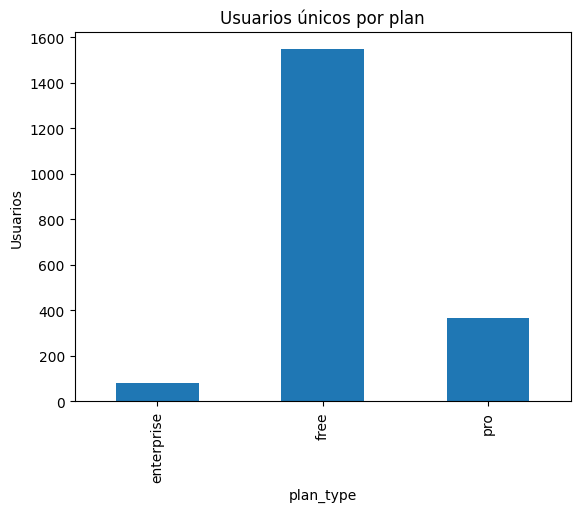

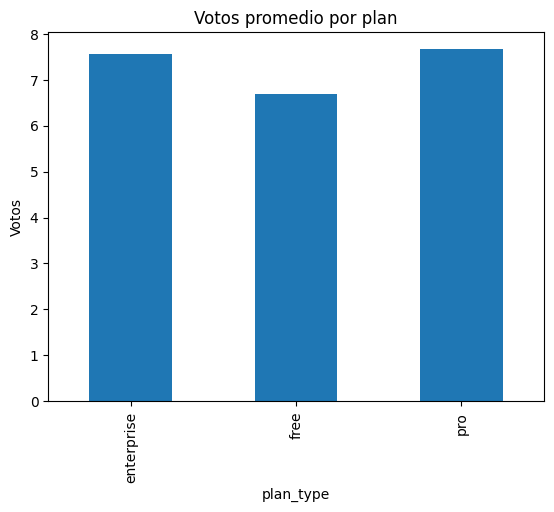

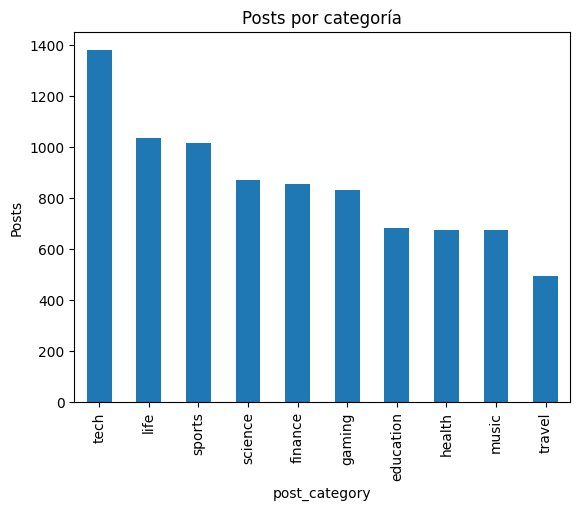

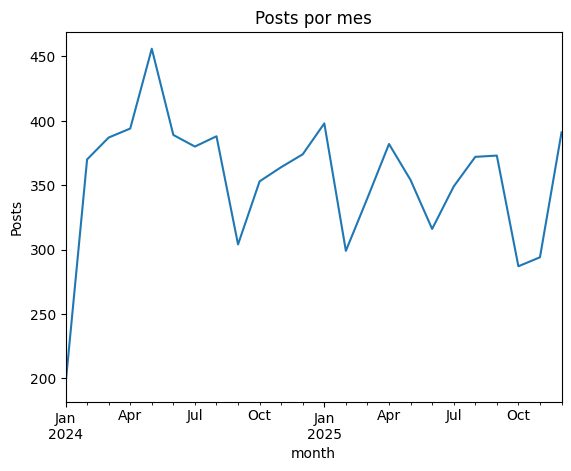

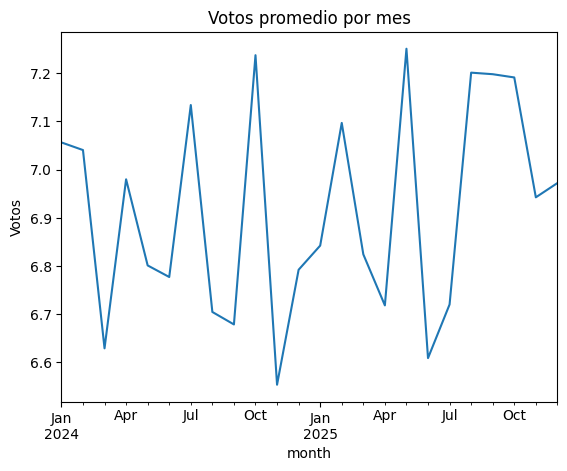

In [20]:
users_per_plan.plot(kind='bar', title='Usuarios únicos por plan')
plt.ylabel('Usuarios')
plt.show()

df_clean.groupby('plan_type')['votes_received'].mean().plot(kind='bar', title='Votos promedio por plan')
plt.ylabel('Votos')
plt.show()

posts_by_category.plot(kind='bar', title='Posts por categoría')
plt.ylabel('Posts')
plt.show()

monthly['posts'].plot(title='Posts por mes')
plt.ylabel('Posts')
plt.show()

monthly['avg_votes'].plot(title='Votos promedio por mes')
plt.ylabel('Votos')
plt.show()